# How the genre counts change through the labeling

*Temporary notebook, to be merged into [main.ipynb](main.ipynb) after the "dataset at a glance" overview.*

In `figures/overview.png`, *pop* has far more songs than *r&b*, but after labeling `rb` is larger than `pop`. The overview counts the **literal** primary genre name, while the labels group many MusicBrainz genres into one class (soul, funk, disco, motown, gospel ... all become `rb`). The steps:

1. **primary genre = tag name**: the primary genre is literally `rock`, `pop`, `r&b`, `country` or `hip hop` (the bars in the overview)
2. **primary genre → its class**: the primary genre mapped to its coarse class (`COARSE_GENRES` in `src/combine.py`)
3. **votes over all genres** (`genre_coarse`): votes of *all* the song's genres summed per class; the top class wins (jazz, folk, reggae ... can still win)
4. **mb_label**: as step 3, but only the five Genius tags compete
5. **with Genius lyrics**: `mb_label` and lyrics found
6. **in the analysis**: the songs the lyrics network and classifier use (rap dropped)

,1. primary genre = tag name,2. primary genre → its class,3. votes over all genres,4. mb_label (5 tags only),5. with Genius lyrics,6. in the analysis (no rap)
rock,5917,8490,8533,8865,4228,4228
pop,1766,2055,1928,2168,792,792
rb,181,2732,2806,3017,1363,1363
country,1257,1360,1406,1546,671,671
rap,40,40,35,36,20,0


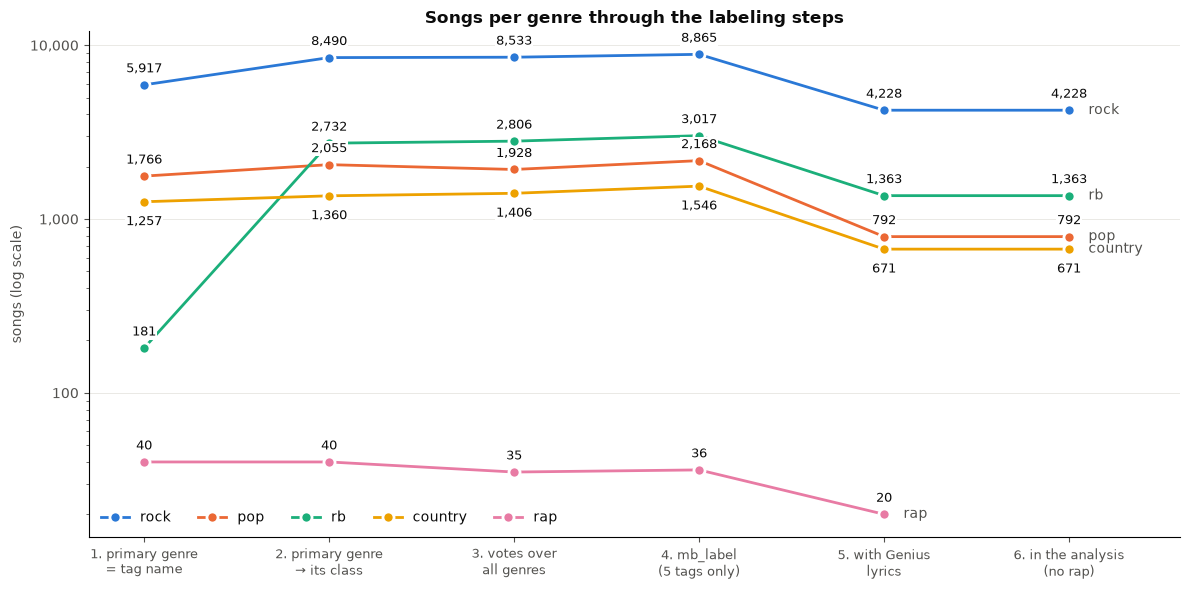

In [1]:
import pandas as pd
from IPython.display import display

from src import exploration
from src.data import load_data

%matplotlib inline

songs, genius = load_data()
steps = exploration.label_steps(songs)
display(steps.rename(columns=lambda c: c.replace("\n", " ")))
exploration.plot_label_steps(steps);

### Which genres are combined in each class?
Step 2 above: every MusicBrainz primary genre mapped to its coarse class (`COARSE_GENRES` in `src/combine.py`), with its number of songs. *genres* is how many distinct primary genres the class combines; the 15 largest are listed. The five Genius tags come first. The other classes can only win in step 3, and are dropped in step 4, where a song gets its most-voted Genius tag instead.

In [2]:
with pd.option_context("display.max_colwidth", None):
    display(exploration.class_members(songs).style.set_properties(
        subset=["primary genres"], **{"text-align": "left", "white-space": "normal"}))

,songs,genres,primary genres
rock,8490,27,"rock (5,917), punk (1,543), wave (402), metal (126), pigfuck (100), mod (80), rockabilly (78), nederbeat (76), christian hardcore (53), krautrock (32), glam (17), palingsound (12), aor (9), oi (8), beat music (7), ... +12 more"
pop,2055,11,"pop (1,766), europop (66), schlager (61), ballad (38), easy listening (35), nederpop (33), levenslied (23), chanson française (15), idol kayō (8), kayōkyoku (8), cantopop (2)"
rb,2732,10,"soul (1,469), disco (633), funk (378), r&b (181), doo-wop (27), gospel (26), motown (9), hi-nrg (5), quiet storm (3), boogie (1)"
country,1360,5,"country (1,257), nashville sound (60), bluegrass (33), western (9), honky tonk (1)"
rap,40,1,hip hop (40)
reggae,484,6,"reggae (333), ska (71), rocksteady (50), dub (21), calypso (5), dancehall (4)"
jazz,406,5,"jazz (386), swing (11), big band (5), ragtime (2), lounge (2)"
folk,367,5,"singer-songwriter (179), folk (157), skiffle (26), celtic (3), cajun (2)"
other,221,31,"comedy (38), classical (25), christmas music (22), children's music (18), poetry (16), musical (13), instrumental (10), experimental (10), new age (6), production music (6), latin (6), chimurenga (6), kleinkunst (5), afrobeat (5), neue deutsche welle (5), ... +16 more"
electronic,197,11,"electronic (111), industrial (38), ambient (16), minimal synth (10), electro (9), house (5), synthwave (3), dance (2), moogsploitation (1), berlin school (1), eurobeat (1)"


Step 2 is where `rb` overtakes `pop`: only 181 songs have the primary genre `r&b`, but soul (1,469), disco (633), funk and the other R&B styles join it. Pop gains far less (europop, ballad, schlager ...). Steps 3 and 4 move a few hundred songs more; the lyrics step then roughly halves every genre, and pop loses most (37% of pop songs have lyrics vs 45% of rb).